In [1]:
import cobra
import networkx as nx
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import math
import seaborn as sns

plt.rcParams['figure.figsize'] = [10, 7]

In [7]:
def plot_uptakes(compound, light_corr, carbon_corr, condition):
    plt.rcParams['figure.figsize'] = [9,7]
    plt.rcParams['figure.dpi'] = 200
    C_carbon = 1000 * 0.5 / 12
    if compound.lower() == 'c':
        fig_name = 'u_C_std_VS_prot.png'
        r_id = 'EX_hco3_e'
        u_id = 'u_C'
        label = 'Lower bound for C uptake (mmol·gDW⁻¹·h⁻¹)'
    elif compound.lower() == 'n':
        fig_name = 'u_N_std_VS_prot.png'
        r_id = 'EX_nh4_e'
        u_id = 'u_N'
        label = 'Lower bound for N uptake (mmol·gDW⁻¹·h⁻¹)'
    else:
        raise ValueError('Compound parameter should be either C or N')
    
    if light_corr:
        light_corr_1 = 12/21
        light_corr_2 = 48/90
    else:
        light_corr_1 = 1
        light_corr_2 = 1
    
    if carbon_corr:
        carbon_corr_1 = 21/12
        carbon_corr_2 = 90/48
    else:
        carbon_corr_1 = 1
        carbon_corr_2 = 1
 
    if compound.lower() == 'n':
        carbon_corr_1 = light_corr_1
        carbon_corr_2 = light_corr_2
        
    # standard
    i = 0
    n = 0
    stop = False
    u_min = []
    u_max = []
    growth = []
    optimal_value = 1
    
    if condition == 'std': 
        model_id = 'models/iJN678_std.json'
    else: 
        model_id = 'models/iJN678_prot.json'
    while i<=optimal_value:
        model = cobra.io.load_json_model(model_id)
        model.solver='glpk'
       # model.reactions.Diff_nh4_e.delete()
        if condition == 'std':
            model.reactions.EX_o2_e.lower_bound = -1000
            model.reactions.EX_hco3_e.lower_bound = -13
            model.reactions.EX_so4_e.lower_bound = -217 
            model.reactions.EX_nh4_e.lower_bound = -1.9 
            
        else:
            model.reactions.EX_so4_e.lower_bound = -143
            model.reactions.EX_nh4_e.lower_bound = -200
            model.reactions.EX_hco3_e.lower_bound = -13
            model.reactions.EX_o2_e.lower_bound = 0
            
        model.reactions.EX_glc__D_e.lower_bound = 0
        model.reactions.EX_photon_e.lower_bound = -23 #*light_corr_1
        model.reactions.EX_co2_e.lower_bound = 0
        model.reactions.EX_no3_e.lower_bound = 0
       
    
      #  ATP_m = cobra.Reaction(id = 'ATPM', name = 'ATP maintenance', 
      #                         lower_bound=0.13, upper_bound=0.13)
      #  ATP_m.add_metabolites({model.metabolites.atp_c:-1,model.metabolites.h2o_c:-1,
      #                      model.metabolites.adp_c:1, model.metabolites.h_c:1,
      #                      model.metabolites.pi_c:1})
      #  model.add_reactions([ATP_m])
        
        model.objective = model.reactions.BIOMASS_Ec_SynAuto
        optimal_value = model.optimize().objective_value
        
        model.reactions.BIOMASS_Ec_SynAuto.bounds = (i, i)
        model.objective = model.reactions.get_by_id(r_id)
    
        if not stop and model.optimize().status == 'infeasible':
            stop = n
            
        minimum = - model.optimize().objective_value
        maximum = - model.optimize(objective_sense='minimize').objective_value
        
        u_min.append(minimum)
        u_max.append(maximum)
        growth.append(i)
    
        if i!=optimal_value and i+0.05 > optimal_value:
            i = optimal_value
        else:
            i += 0.05
            
        n += 1
        
    
    if not stop:
        stop = len(growth)
        
    slope_std = (u_min[-1]-u_min[0])/(growth[-1]-growth[0])
    

    color12 = (0.0, 0.5, 0.5, 0.35)
    color4 = (0.8, 0.4, 0.6, 0.4)

    if condition=='std':
        plt.plot(growth[:stop+1], u_min[:stop+1], color = color12, linewidth=2, alpha=1)
        #plt.plot(growth[:stop+1], u_max[:stop+1], color = color12, linewidth=2, alpha=1)

        
    
    max_line_std = [growth[:stop+1], u_max[:stop+1]]
    min_line_std = [growth[:stop+1], u_min[:stop+1]]
    
    max_g_1 = max(growth)
    u_max_1 = max(u_max)
    
    
    if condition == 'std':
        df3 = pd.read_csv('results_new/results_std_corrected_12h_PEAKS.dat', sep='\t')
    else:
        df = pd.read_csv('results/results_'+condition+'.dat', sep='\t')
    clusters = pd.read_csv('results/cluster_labels_'+condition+'.dat', sep='\t', header=None, dtype=int)
    if condition == 'std':
        clusters = pd.read_csv('results_new/clusters_4to12h_N_NEW.dat', sep='\t')
    else:
        clusters = pd.read_csv('results/cluster_labels_prot.dat', sep='\t', header=None, dtype=int)
    dfs = []
    if condition == 'std':
        n_clusters = 2
    else: 
        n_clusters = 2
        
    for i in range(0,n_clusters):
        dfs.append(df3[clusters['cluster']==i])

    if condition == 'std':
        darkblue_transparent = (0.0, 0.0, 0.55, 0.4)     # darkblue with alpha
        darkorange_transparent = (1.0, 0.55, 0.0, 0.5)   # darkorange with alpha
        cmap = plt.cm.coolwarm
        color_peak1 = cmap(0.0)[:3] + (0.45,)   # coolwarm dark blue -> Peak 1
        color_peak2 = cmap(1.0)[:3] + (0.45,)   # coolwarm dark red  -> Peak 2
        colors = [color_peak1, color_peak2]
    else: 
        colors = ['#6be838', 'red']
    
    if condition == 'std':
        cluster_labels = ['4h', '12 h']
        cluster_labels = ['Cluster 1', 'Cluster 2']
       # average_labels = ['Previous average', 'New average']
        colors_average = ['red','black']
        #cluster_labels = ['Low growth NoCe', 'NoCe', 'Low growth CoNe', 'CoNe']
    else: 
        cluster_labels = ['NoCe', 'CoNe']
    scatters = []
    for i,df in enumerate(dfs): 
        scatt = plt.errorbar([g for g in df['g']], [u*carbon_corr_1 for u in df[u_id]], 
                 xerr = df['sd'], elinewidth=0.15,  marker = 'o', ecolor = 'black', barsabove=False,
                 markersize = 11, markeredgewidth=0.2, markeredgecolor='black', capsize=2, linestyle = 'None', 
                label = cluster_labels[i], color = colors[i], alpha=0.7)
        scatters.append(scatt)

    plt.scatter([np.mean(df3['g'])], [np.mean(df3[u_id])], 
            marker = 'X', s = 400, 
            label = 'Population mean', color = 'black', alpha=0.8, zorder=5,  linewidths=0.3,
    edgecolors='black' )
        #scatt = plt.scatter([g for g in df['g']], [u*carbon_corr_1 for u in df[u_id]], 
        #         marker = 'o', s = 1,label = cluster_labels[i], color = colors[i], alpha=0.8)
        

    plt.xlim((0,0.08))
    if condition == 'std':
        if compound == 'C':
            for i,df in enumerate(dfs):
                plt.ylim((0,3))
                plt.plot(np.linspace(optimal_value,optimal_value,100), 
                         np.linspace(1.98,10,100), alpha=1, 
                         color = color12, linewidth=2)
        else: 
            for i,df in enumerate(dfs):
                plt.ylim((0,1.65))
                plt.plot(np.linspace(optimal_value,optimal_value,100), 
                         np.linspace(0.395,2,100), alpha=1,
                         color = color12,linewidth=2)
    
    if condition == 'std':
        plt.fill_between(min_line_std[0], min_line_std[1],10, color = color12,alpha=0.08)
    else:
        plt.fill_between(min_line_std[0], min_line_std[1], 2, color = 'darkorange',alpha=0.08)


    plt.xlabel('Growth rate (h⁻¹)', fontsize=16)
    plt.ylabel(label, fontsize=16)
    plt.legend(fontsize=16,loc='lower right')
    plt.xticks(fontsize=16, rotation=20)
    plt.yticks(fontsize=16)
    plt.savefig(fig_name, dpi=200)
    plt.show()
    
    return slope_std, max_line_std, min_line_std

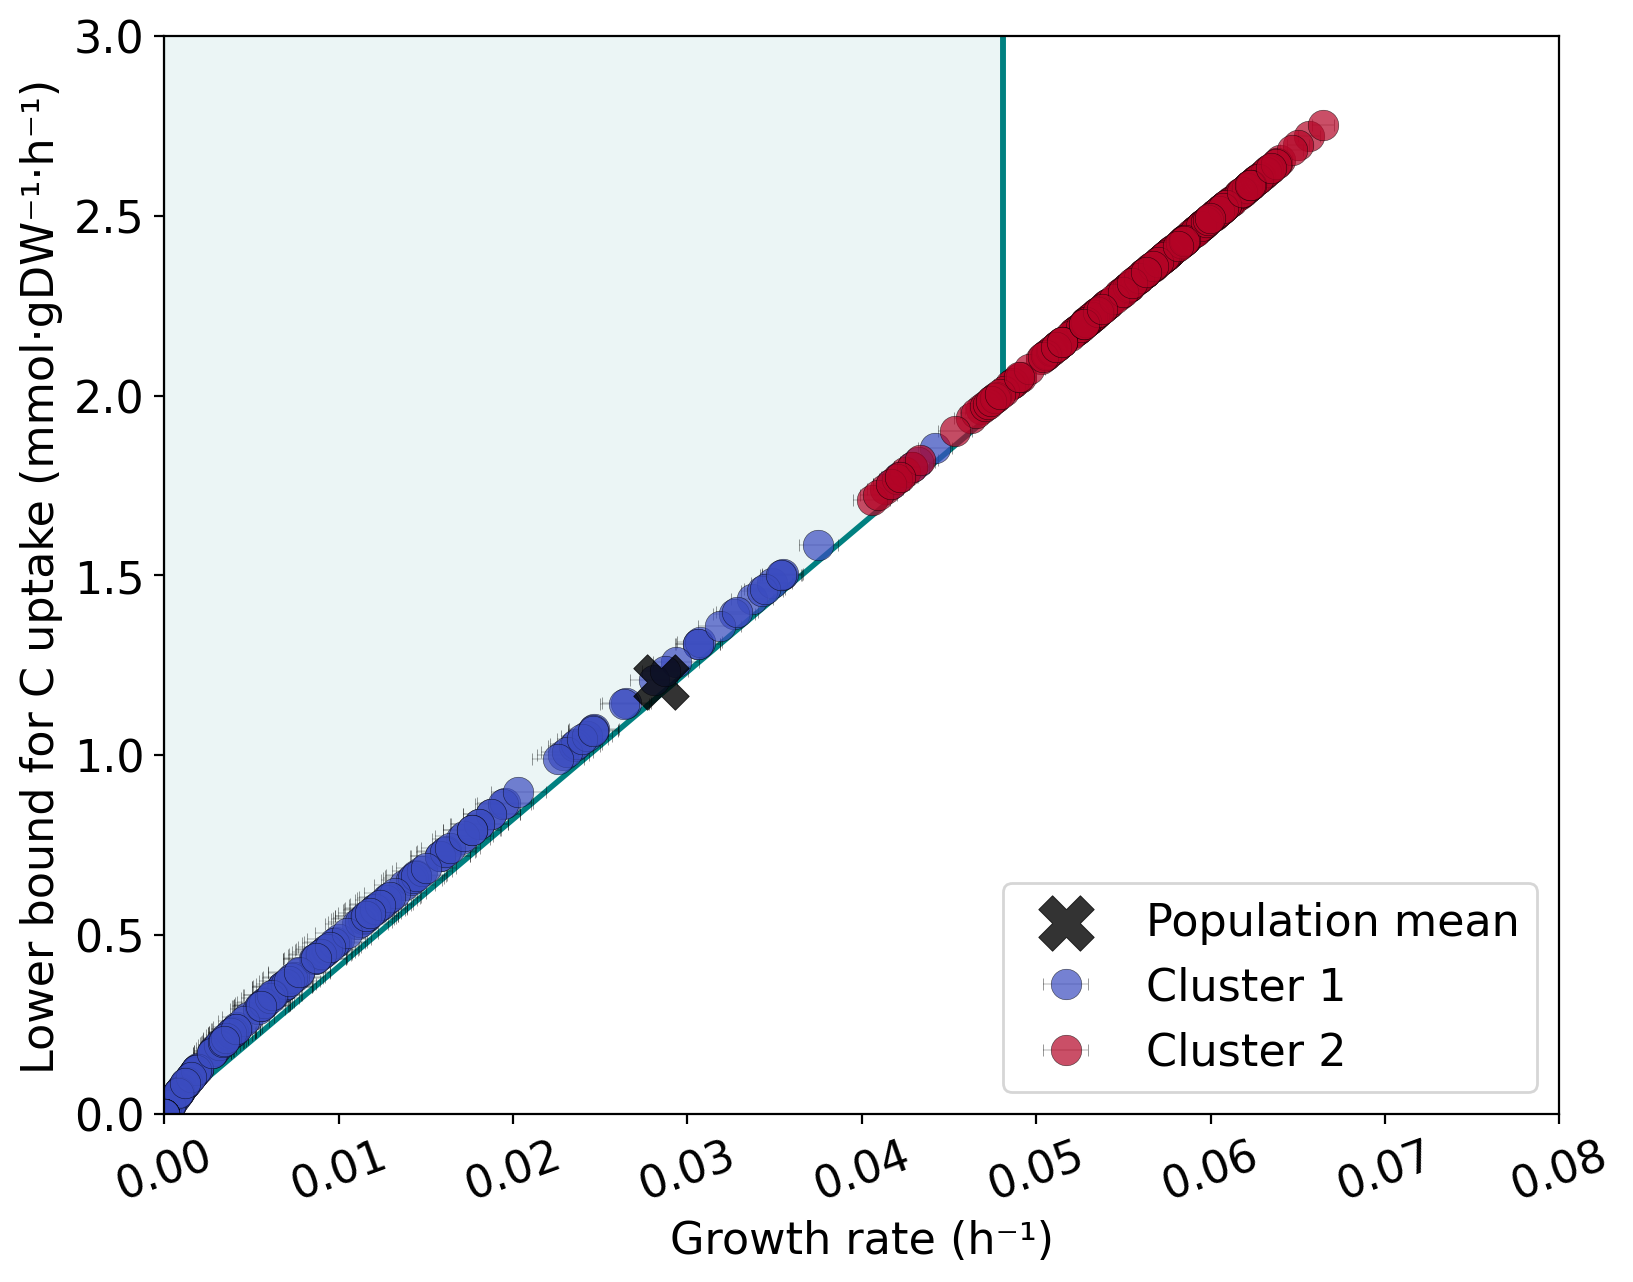

In [8]:
slope_std, max_line_std, min_line_std = plot_uptakes(compound='C', light_corr=False, 
                                                     carbon_corr=False, condition = 'std')

/home/arianferrero/.local/lib/python3.10/site-packages/cobra/util/solver.py:554: UserWarning: Solver status is 'infeasible'.
  warn(f"Solver status is '{status}'.", UserWarning)


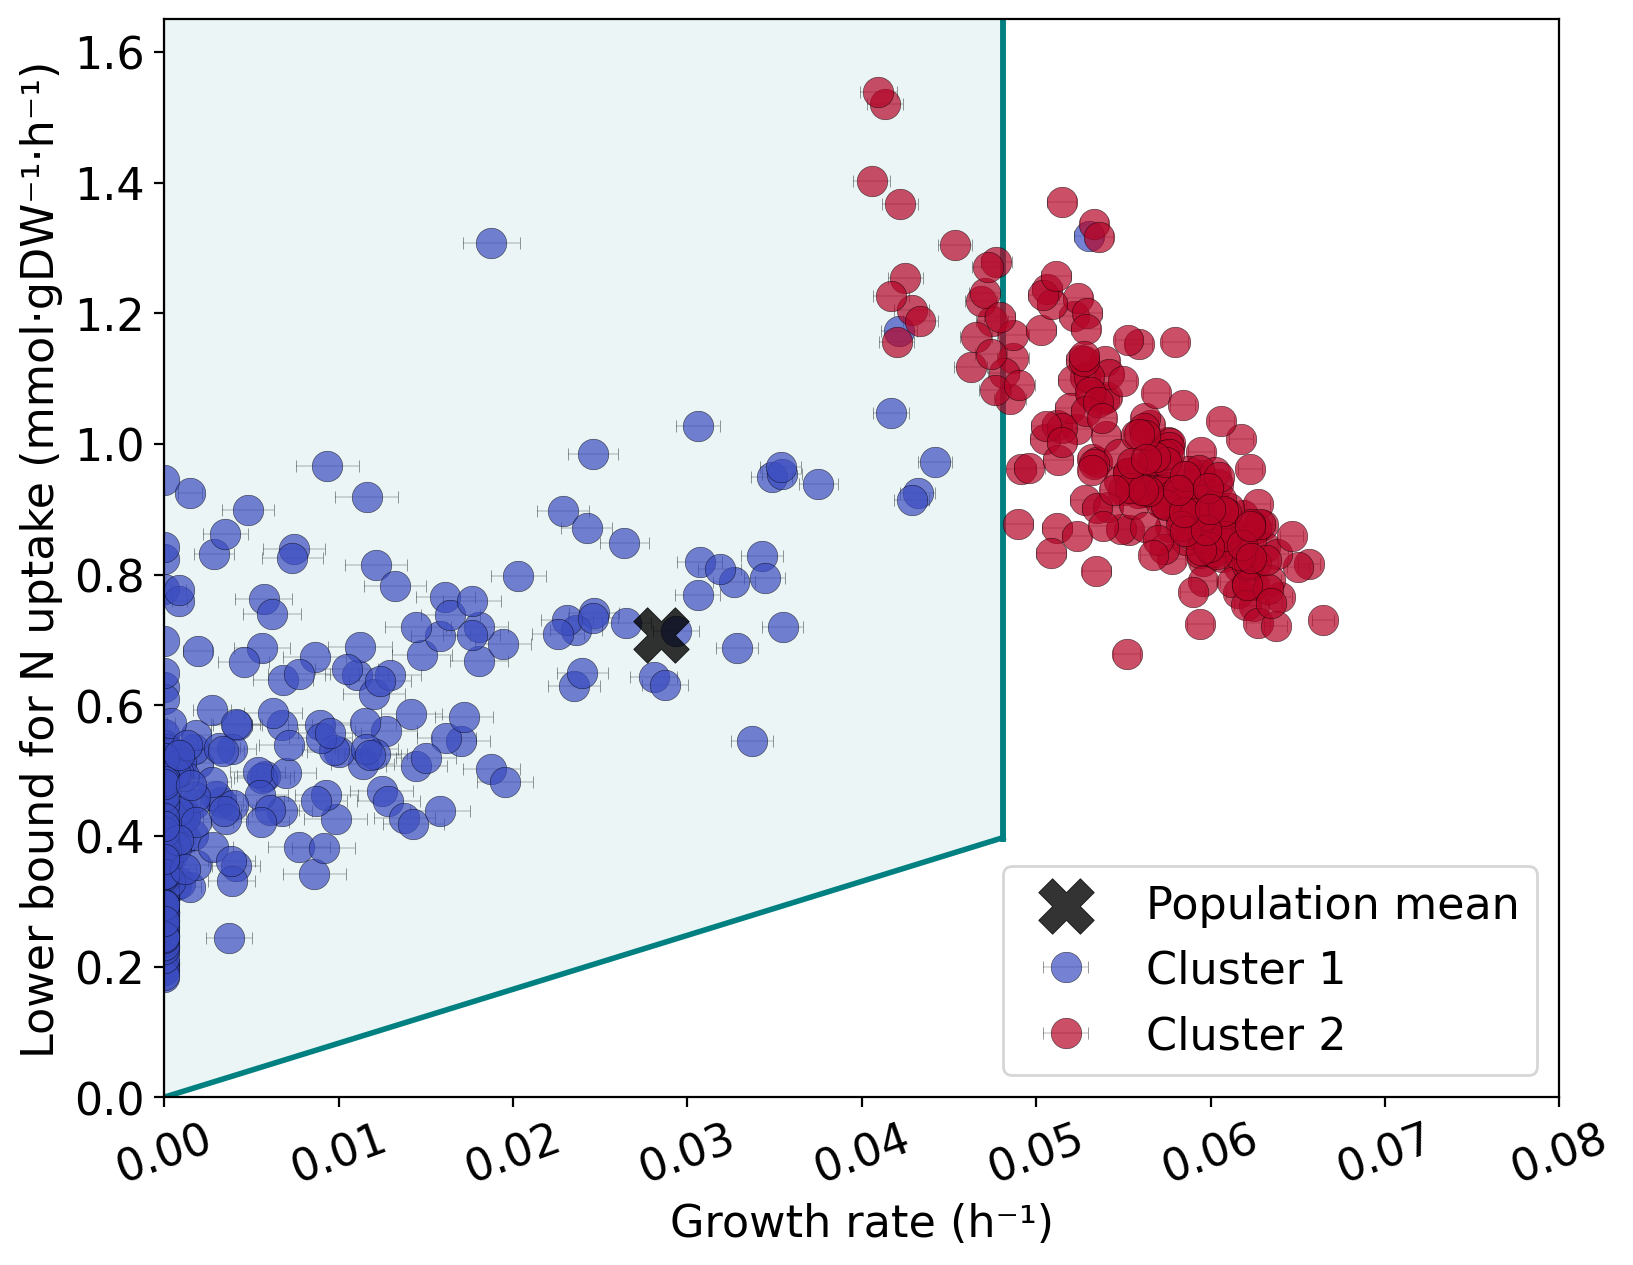

In [9]:
slope_std, max_line_std, min_line_std = plot_uptakes(compound='N', light_corr=False, 
                                                     carbon_corr=False, condition = 'std')

In [23]:
#light_corr = 21/12
#C_carbon = 1000 * 0.5 / 12
model = cobra.io.load_json_model('models/iJN678_std_aminoacids.json')
model.solver = 'glpk'
model.reactions.EX_o2_e.lower_bound = 0
model.reactions.EX_glc__D_e.lower_bound = 0
model.reactions.EX_photon_e.lower_bound = -23 #* light_corr
model.reactions.EX_co2_e.lower_bound = 0# * light_corr
model.reactions.EX_hco3_e.lower_bound = -100
model.reactions.EX_no3_e.lower_bound = 0
model.reactions.EX_so4_e.lower_bound = -217#* light_corr
model.reactions.EX_nh4_e.lower_bound = -1000# * light_corr
#ATP_m = cobra.Reaction(id = 'ATPM', name = 'ATP maintenance', 
#                       lower_bound=0.13, upper_bound=0.13)
#ATP_m.add_metabolites({model.metabolites.atp_c:-1,model.metabolites.h2o_c:-1,
#                    model.metabolites.adp_c:1, model.metabolites.h_c:1,
#                    model.metabolites.pi_c:1})
#model.add_reactions([ATP_m])
model.objective = model.reactions.BIOMASS_Ec_SynAuto
optimal_value = model.optimize().objective_value
    
points = []

c = 0
while c<=10: 
    n = 0
    
    while n<= 2: 
        #if n<c:
        print(c,n)
        model = cobra.io.load_json_model('models/iJN678_std_aminoacids.json')
        model.reactions.EX_o2_e.lower_bound = -1000
        model.reactions.EX_glc__D_e.lower_bound = 0
        model.reactions.EX_photon_e.lower_bound = -23 # * light_corr
        model.reactions.EX_co2_e.lower_bound = 0
        model.reactions.EX_hco3_e.bounds = (-c,-c)
        model.reactions.EX_no3_e.lower_bound = 0
        model.reactions.EX_so4_e.lower_bound = -217# * light_corr
        model.reactions.EX_nh4_e.bounds = (-n,-n)
    
        model.objective = model.reactions.BIOMASS_Ec_SynAuto
        model.solver='glpk'
        try: 
            g = model.optimize().objective_value
            #print(g)
            points.append([c,n,g])
        except: 
            pass
            
        n+= 0.1
    
    c += 0.5

df = pd.DataFrame(points)
df.to_csv('results_new/feasibility_std.dat', sep='\t', header=['C', 'N', 'G'], index=False)

0 0
0 0.1
0 0.2
0 0.30000000000000004


KeyboardInterrupt: 

In [ ]:
"""
C/N feasibility scan (grid over EX_hco3_e and EX_nh4_e bounds), rewritten to be:

1) much faster:
   - the model is loaded from JSON ONCE, not once per (C, N) point (441 points
     in the original grid -> 441 JSON loads). Re-parsing a genome-scale model
     is typically far slower than actually solving the LP, so this is the
     single biggest win here.
   - only the two bounds that actually change (EX_hco3_e, EX_nh4_e) are set
     inside the loop; everything else is configured once on the shared model.
   - model.slim_optimize() is used instead of model.optimize(): it returns
     just the objective value without building the full Solution object
     (fluxes, reduced costs, shadow prices for every reaction), which is all
     wasted work here since only the growth rate is kept.

2) crash-safe: each (C, N, G) row is written to the output file and flushed
   to disk immediately after it's computed, instead of being collected in a
   list and only written out at the very end. If the process dies partway
   through, everything computed so far is already on disk.

3) resumable: on startup, if the output file already exists, it's read back
   in and every (C, N) pair already present is skipped -- so re-running the
   script after a crash (or just to extend the grid) picks up where it left
   off instead of recomputing everything.

Requires: cobra, numpy, pandas
"""
import os
import csv

import numpy as np
import pandas as pd
import cobra

MODEL_PATH = 'models/iJN678_std_aminoacids.json'
OUTPUT_PATH = 'results_new/feasibility_std_NEW.dat'

# grid definition -- np.linspace + rounding avoids the classic
# `n += 0.1` floating point drift (0.1 isn't exact in binary, so a
# `while n <= 2` loop can silently run one iteration short/long).
C_VALUES = np.round(np.linspace(0, 10, 21), 2)   # 0, 0.5, ..., 10.0
N_VALUES = np.round(np.linspace(0, 2, 21), 2)    # 0, 0.1, ..., 2.0


def build_model():
    """Load the model once and set every bound that stays fixed across the
    whole scan. Only EX_hco3_e / EX_nh4_e get touched inside the loop."""
    model = cobra.io.load_json_model(MODEL_PATH)
    model.solver = 'glpk'
    model.reactions.EX_o2_e.lower_bound = -1000
    model.reactions.EX_glc__D_e.lower_bound = 0
    model.reactions.EX_photon_e.lower_bound = -23
    model.reactions.EX_co2_e.lower_bound = 0
    model.reactions.EX_no3_e.lower_bound = 0
    model.reactions.EX_so4_e.lower_bound = -217
    model.objective = model.reactions.BIOMASS_Ec_SynAuto
    return model


def reference_optimum():
    """One-off chcdeck under the original photoautotrophic bounds (O2 exchange
    blocked, hco3/nh4 essentially unbounded) -- independent of the scan grid,
    kept only for reference/logging like in the original script."""
    model = cobra.io.load_json_model(MODEL_PATH)
    model.solver = 'glpk'
    model.reactions.EX_o2_e.lower_bound = 0
    model.reactions.EX_glc__D_e.lower_bound = 0
    model.reactions.EX_photon_e.lower_bound = -23
    model.reactions.EX_co2_e.lower_bound = 0
    model.reactions.EX_hco3_e.lower_bound = -100
    model.reactions.EX_no3_e.lower_bound = 0
    model.reactions.EX_so4_e.lower_bound = -217
    model.reactions.EX_nh4_e.lower_bound = -1000
    model.objective = model.reactions.BIOMASS_Ec_SynAuto
    return model.slim_optimize()


def load_done_pairs(path):
    """Read whatever's already in the output file (if it exists) and return
    the set of (C, N) pairs already computed, so the scan can skip them."""
    if not os.path.exists(path) or os.path.getsize(path) == 0:
        return set()
    done = pd.read_csv(path, sep='\t')
    return set(zip(np.round(done['C'], 2), np.round(done['N'], 2)))


def main():
    os.makedirs(os.path.dirname(OUTPUT_PATH), exist_ok=True)

    done = load_done_pairs(OUTPUT_PATH)
    if done:
        print(f"Resuming: {len(done)} (C, N) pairs already computed, skipping those.")

    optimal_value = reference_optimum()
    print(f"Reference optimum (unbounded C/N, O2 blocked): {optimal_value}")

    model = build_model()
    hco3 = model.reactions.EX_hco3_e
    nh4 = model.reactions.EX_nh4_e

    file_exists = os.path.exists(OUTPUT_PATH) and os.path.getsize(OUTPUT_PATH) > 0

    # 'a' (append) + line buffering-by-flush so a killed process never loses
    # more than the single row currently in flight.
    with open(OUTPUT_PATH, 'a', newline='') as f:
        writer = csv.writer(f, delimiter='\t')
        if not file_exists:
            writer.writerow(['C', 'N', 'G'])
            f.flush()

        for c in C_VALUES:
            for n in N_VALUES:
                if (c, n) in done:
                    continue

                hco3.bounds = (-c, -c)
                nh4.bounds = (-n, -n)

                try:
                    g = model.slim_optimize()  # NaN (not a raise) if infeasible
                except Exception:
                    g = float('nan')

                print(c, n, g)

                if g is None or np.isnan(g):
                    continue  # matches the original: infeasible points are skipped

                writer.writerow([c, n, g])
                f.flush()
                os.fsync(f.fileno())  # survive a hard kill, not just an exception
                done.add((c, n))


if __name__ == '__main__':
    main()

In [46]:
import plotly
print(plotly.__version__)

7.0.0


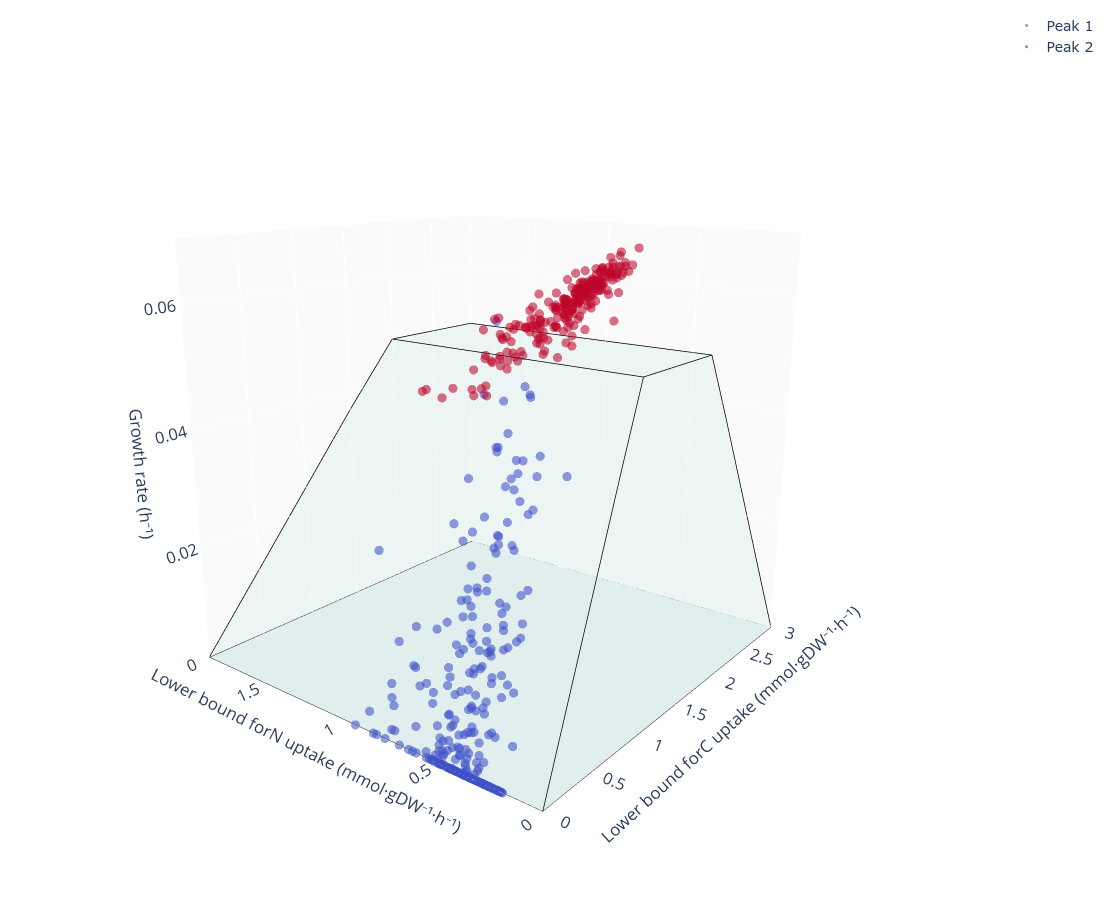

In [10]:
import numpy as np
import pandas as pd
import plotly.graph_objects as go
import matplotlib.pyplot as plt
from scipy.spatial import ConvexHull
from collections import defaultdict

# =========================
# Load feasibility polytope
# =========================

points = pd.read_csv('results_new/feasibility_std_NEW.dat', sep='\t')
points.columns = ['C', 'N', 'G']

# =========================
# Visible axis ranges -- defined ONCE here and reused both for the scene
# layout below AND for computing the plane-cut wireframe segments, so the
# cut lines can never drift out of sync with what's actually visible.
# =========================

X_RANGE = [0, 3]
Y_RANGE = [0, 1.9]
Z_RANGE = [0, 0.07]

# =========================
# Figure
# =========================

fig = go.Figure()

# --- build one 3D point cloud: the real growth-rate surface + its floor twin ---
floor_x = np.concatenate([points['C'], points['C']])
floor_y = np.concatenate([points['N'], points['N']])
floor_z = np.concatenate([points['G'], np.zeros(len(points))])
pts_3d = np.column_stack([floor_x, floor_y, floor_z])

# compute the actual polytope in Python (scipy), instead of leaving the
# triangulation to alphahull in the browser -- this is what both the shaded
# faces AND the wireframe edges below are built from, so they always agree
hull = ConvexHull(pts_3d)
face_i, face_j, face_k = hull.simplices[:, 0], hull.simplices[:, 1], hull.simplices[:, 2]

fig.add_trace(
    go.Mesh3d(
        x=pts_3d[:, 0], y=pts_3d[:, 1], z=pts_3d[:, 2],
        i=face_i, j=face_j, k=face_k,
        opacity=0.15,
        color="rgba(0,128,128,0.35)",
        flatshading=True,
        name='Feasibility polytope',
        hoverinfo='skip',
        showscale=False
    )
)

# =========================
# Boundary edges -- derived from the SAME hull as the mesh above, so they
# always trace exactly the edges of the feasibility region (no more
# hand-typed coordinates that can drift out of sync with the data)
# =========================

def hull_feature_edges(hull, angle_tol_deg=1.0):
    """
    Only the 'sharp' edges of the hull -- where two adjacent triangles meet
    at a real corner of the polytope -- skipping the internal edges that
    just split a flat face (like the floor or the top plateau) into
    triangles.
    """
    edge_faces = defaultdict(list)
    for face_idx, simplex in enumerate(hull.simplices):
        for a, b in [(simplex[0], simplex[1]), (simplex[1], simplex[2]), (simplex[2], simplex[0])]:
            edge = tuple(sorted((int(a), int(b))))
            edge_faces[edge].append(face_idx)
    normals = hull.equations[:, :3]
    cos_tol = np.cos(np.radians(angle_tol_deg))
    edges = []
    for edge, faces in edge_faces.items():
        if len(faces) == 2:
            n1, n2 = normals[faces[0]], normals[faces[1]]
            if np.dot(n1, n2) < cos_tol:
                edges.append(edge)
        else:
            edges.append(edge)
    return edges


def hull_plane_cut_edges(hull, pts_3d, axis, value, eps=1e-9):
    """
    Cross-section of the hull with the plane `pts_3d[:, axis] == value`,
    returned as a list of (point_a, point_b) segments.

    Used to draw a clean boundary line wherever the mesh actually gets
    clipped by the visible axis range (e.g. the C axis being cropped to
    [0, 3] while the underlying data extends to C=10) -- otherwise Plotly
    just silently cuts the mesh off there with no marked edge.

    Triangles that lie ENTIRELY in the cutting plane are skipped: those are
    real hull faces coincident with the plane (e.g. the z=0 floor, or a
    C=0/N=0 wall if the data starts exactly at the axis origin), not a cut
    -- their boundary is already traced by hull_feature_edges above, so
    including them here would just redraw the internal triangulation lines
    of that flat face.
    """
    d = pts_3d[:, axis] - value
    segments = []
    for simplex in hull.simplices:
        ds = d[simplex]
        signs = np.sign(np.where(np.abs(ds) < eps, 0, ds))
        if not (1 in signs and -1 in signs):
            # the plane doesn't actually pass through this triangle's
            # interior -- either the whole triangle is coincident with it
            # (a real face, e.g. the z=0 floor -- already traced by
            # hull_feature_edges) or the plane only touches one vertex
            # without slicing across (not a genuine cut)
            continue
        cross_pts = []
        for a_idx in range(3):
            b_idx = (a_idx + 1) % 3
            da, db = ds[a_idx], ds[b_idx]
            if abs(da) < eps:
                cross_pts.append(pts_3d[simplex[a_idx]])
            elif da * db < 0:
                t = da / (da - db)
                cross_pts.append(pts_3d[simplex[a_idx]] + t * (pts_3d[simplex[b_idx]] - pts_3d[simplex[a_idx]]))
        if len(cross_pts) >= 2:
            segments.append((cross_pts[0], cross_pts[1]))
    return segments


feature_edges = hull_feature_edges(hull)

edge_x, edge_y, edge_z = [], [], []
for a, b in feature_edges:
    edge_x += [pts_3d[a, 0], pts_3d[b, 0], None]
    edge_y += [pts_3d[a, 1], pts_3d[b, 1], None]
    edge_z += [pts_3d[a, 2], pts_3d[b, 2], None]

# add cut lines wherever the hull actually crosses one of the visible axis
# range boundaries (a no-op for any plane the hull doesn't reach, e.g. the
# z-axis upper range if growth rate never gets that high)
for axis, rng in zip((0, 1, 2), (X_RANGE, Y_RANGE, Z_RANGE)):
    for value in rng:
        for p_a, p_b in hull_plane_cut_edges(hull, pts_3d, axis, value):
            edge_x += [p_a[0], p_b[0], None]
            edge_y += [p_a[1], p_b[1], None]
            edge_z += [p_a[2], p_b[2], None]

fig.add_trace(
    go.Scatter3d(
        x=edge_x,
        y=edge_y,
        z=edge_z,
        mode='lines',
        line=dict(color='black', width=1.5),
        showlegend=False,
        hoverinfo='skip'
    )
)

# =========================
# Experimental data -- split by cluster
# =========================

df2 = pd.read_csv(
    'results_new/results_std_corrected_12h_PEAKS.dat',
    sep='\t'
).reset_index(drop=True)

clusters = pd.read_csv(
    'results_new/clusters_4to12h_N_NEW.dat',
    sep='\t'
).reset_index(drop=True)
# .reset_index(drop=True) on BOTH above is what makes the boolean mask below
# line up by *position* rather than by whatever index each file happened to
# come in with -- if df2 and clusters weren't built row-for-row in the same
# order to begin with, this still won't fix that, but it removes index
# mismatches as a source of silently-empty/misaligned subsets.

dfs = [df2[clusters['cluster'].to_numpy() == i].reset_index(drop=True) for i in range(2)]

# --- Colors ---
# plt.cm.coolwarm(...) returns a matplotlib RGBA tuple with components in
# 0-1 (e.g. (0.129, 0.400, 0.674, 1.0)). Plotly's marker.color does NOT
# understand that -- it wants a CSS-style string ("rgb(...)", "rgba(...)",
# hex, or a named color). Handing it a raw float tuple is why the cluster
# markers weren't painting: this converts it to a string Plotly can use.
def mpl_to_rgba_str(rgba, alpha=None):
    r, g, b = rgba[:3]
    a = alpha if alpha is not None else (rgba[3] if len(rgba) > 3 else 1.0)
    return f'rgba({int(round(r*255))},{int(round(g*255))},{int(round(b*255))},{a})'

cmap = plt.cm.coolwarm
color_peak1 = mpl_to_rgba_str(cmap(0.0), alpha=0.95)   # coolwarm dark blue -> Peak 1
color_peak2 = mpl_to_rgba_str(cmap(1.0), alpha=0.95)   # coolwarm dark red  -> Peak 2
colors = [color_peak1, color_peak2]
labels = ['Peak 1', 'Peak 2']   # matches cluster order (0 -> Peak 1, 1 -> Peak 2)

# =========================
# Add data traces
# =========================

for trace_idx, dfi in enumerate(dfs):

    mask = dfi['u_N'] < 10  # note: filters on u_N, not u_C -- keep if intentional
    dfi = dfi[mask]

    fig.add_trace(
        go.Scatter3d(
            x=dfi['u_C'],
            y=dfi['u_N'],
            z=dfi['g'],

            mode='markers',

            name=labels[trace_idx],

            marker=dict(
                size=3,
                color=colors[trace_idx],
                opacity=0.6,
                line=dict(width=0)
            ),

            error_z=dict(
                type='data',
                array=dfi['sd'],
                visible=False,
                color='grey',
                thickness=0.5,
                width=2
            )
        )
    )

# =========================
# Layout
# =========================

fig.update_layout(

    width=900,
    height=900,

    font=dict(size=14),

    margin=dict(
        r=10,
        l=10,
        b=10,
        t=10
    ),

#
    #legend=dict(
    #    x=0.7,
    #    y=0.7,
    #    bgcolor='rgba(255,255,255,0.7)',
    #    font=dict(size=15),
#
    #    itemsizing='constant'   # <-- THIS is what makes legend markers bigger & consistent
    #),


    scene=dict(

        xaxis=dict(
            title='Lower bound for\nC uptake (mmol·gDW⁻¹·h⁻¹)',
            backgroundcolor="#FAFAFA",
            gridcolor="white",
            showbackground=True,
            zerolinecolor="white",
            range=X_RANGE
        ),

        yaxis=dict(
            title='Lower bound for\nN uptake (mmol·gDW⁻¹·h⁻¹)',
            backgroundcolor="#FAFAFA",
            gridcolor="white",
            showbackground=True,
            zerolinecolor="white",
            range=Y_RANGE
        ),

        zaxis=dict(
            title='Growth rate (h⁻¹)',
            backgroundcolor="#FAFAFA",
            gridcolor="white",
            showbackground=True,
            zerolinecolor="white",
            range=Z_RANGE
        ),

        camera=dict(
            eye=dict(x=-1.9, y=-1.5, z=0.7),
            center=dict(x=0, y=0, z=0),
            up=dict(x=0, y=0, z=1)
        )
    )
)

fig.write_html('test_polytope.html')
fig.show()

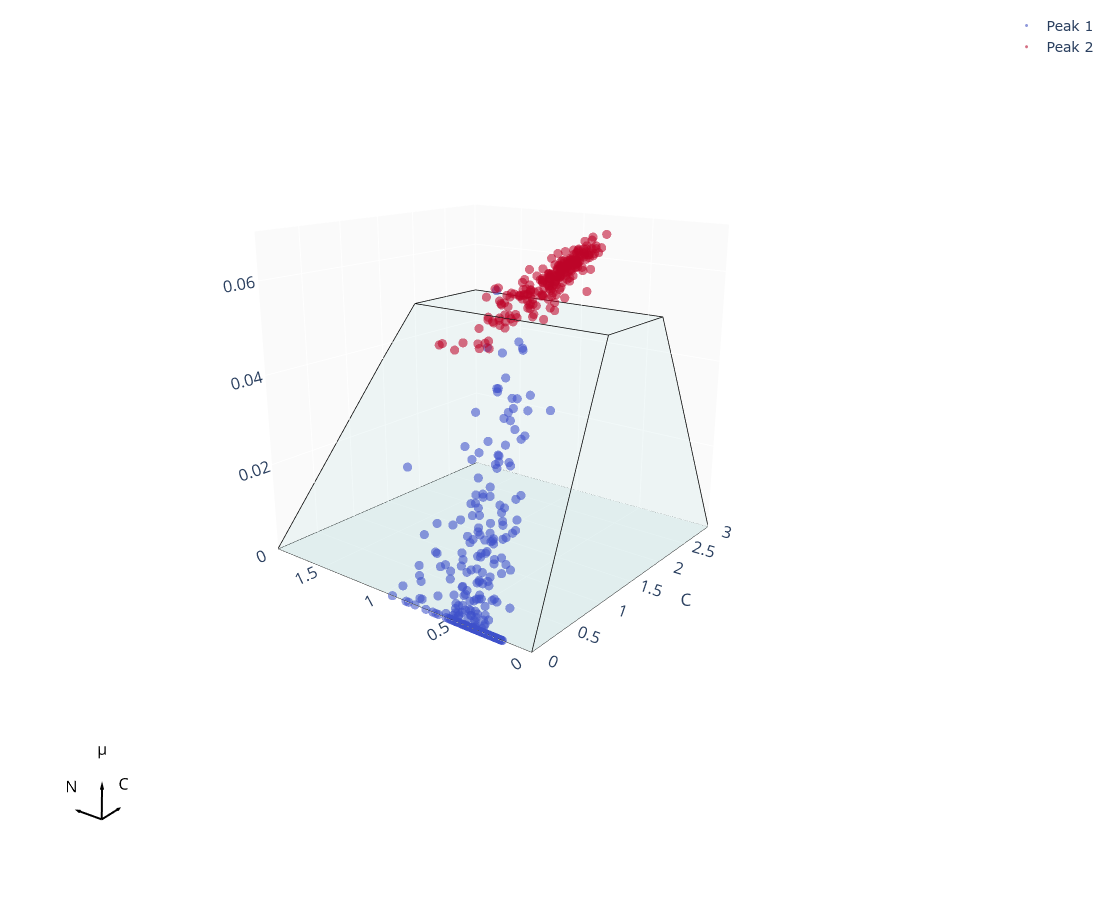

In [17]:
import numpy as np
import pandas as pd
import plotly.graph_objects as go
import matplotlib.pyplot as plt
from scipy.spatial import ConvexHull
from collections import defaultdict

# =========================
# Load feasibility polytope
# =========================

points = pd.read_csv('results_new/feasibility_std_NEW.dat', sep='\t')
points.columns = ['C', 'N', 'G']

# =========================
# Visible axis ranges -- defined ONCE here and reused both for the scene
# layout below AND for computing the plane-cut wireframe segments, so the
# cut lines can never drift out of sync with what's actually visible.
# =========================

X_RANGE = [0, 3]
Y_RANGE = [0, 1.9]
Z_RANGE = [0, 0.07]

# =========================
# Figure
# =========================

fig = go.Figure()

# --- build one 3D point cloud: the real growth-rate surface + its floor twin ---
floor_x = np.concatenate([points['C'], points['C']])
floor_y = np.concatenate([points['N'], points['N']])
floor_z = np.concatenate([points['G'], np.zeros(len(points))])
pts_3d = np.column_stack([floor_x, floor_y, floor_z])

# compute the actual polytope in Python (scipy), instead of leaving the
# triangulation to alphahull in the browser -- this is what both the shaded
# faces AND the wireframe edges below are built from, so they always agree
hull = ConvexHull(pts_3d)
face_i, face_j, face_k = hull.simplices[:, 0], hull.simplices[:, 1], hull.simplices[:, 2]

fig.add_trace(
    go.Mesh3d(
        x=pts_3d[:, 0], y=pts_3d[:, 1], z=pts_3d[:, 2],
        i=face_i, j=face_j, k=face_k,
        opacity=0.15,
        color="rgba(0,128,128,0.35)",
        flatshading=True,
        name='Feasibility polytope',
        hoverinfo='skip',
        showscale=False
    )
)

# =========================
# Boundary edges -- derived from the SAME hull as the mesh above, so they
# always trace exactly the edges of the feasibility region (no more
# hand-typed coordinates that can drift out of sync with the data)
# =========================

def hull_feature_edges(hull, angle_tol_deg=1.0):
    """
    Only the 'sharp' edges of the hull -- where two adjacent triangles meet
    at a real corner of the polytope -- skipping the internal edges that
    just split a flat face (like the floor or the top plateau) into
    triangles.
    """
    edge_faces = defaultdict(list)
    for face_idx, simplex in enumerate(hull.simplices):
        for a, b in [(simplex[0], simplex[1]), (simplex[1], simplex[2]), (simplex[2], simplex[0])]:
            edge = tuple(sorted((int(a), int(b))))
            edge_faces[edge].append(face_idx)
    normals = hull.equations[:, :3]
    cos_tol = np.cos(np.radians(angle_tol_deg))
    edges = []
    for edge, faces in edge_faces.items():
        if len(faces) == 2:
            n1, n2 = normals[faces[0]], normals[faces[1]]
            if np.dot(n1, n2) < cos_tol:
                edges.append(edge)
        else:
            edges.append(edge)
    return edges


def hull_plane_cut_edges(hull, pts_3d, axis, value, eps=1e-9):
    """
    Cross-section of the hull with the plane `pts_3d[:, axis] == value`,
    returned as a list of (point_a, point_b) segments.

    Used to draw a clean boundary line wherever the mesh actually gets
    clipped by the visible axis range (e.g. the C axis being cropped to
    [0, 3] while the underlying data extends to C=10) -- otherwise Plotly
    just silently cuts the mesh off there with no marked edge.

    Triangles that lie ENTIRELY in the cutting plane are skipped: those are
    real hull faces coincident with the plane (e.g. the z=0 floor, or a
    C=0/N=0 wall if the data starts exactly at the axis origin), not a cut
    -- their boundary is already traced by hull_feature_edges above, so
    including them here would just redraw the internal triangulation lines
    of that flat face.
    """
    d = pts_3d[:, axis] - value
    segments = []
    for simplex in hull.simplices:
        ds = d[simplex]
        signs = np.sign(np.where(np.abs(ds) < eps, 0, ds))
        if not (1 in signs and -1 in signs):
            # the plane doesn't actually pass through this triangle's
            # interior -- either the whole triangle is coincident with it
            # (a real face, e.g. the z=0 floor -- already traced by
            # hull_feature_edges) or the plane only touches one vertex
            # without slicing across (not a genuine cut)
            continue
        cross_pts = []
        for a_idx in range(3):
            b_idx = (a_idx + 1) % 3
            da, db = ds[a_idx], ds[b_idx]
            if abs(da) < eps:
                cross_pts.append(pts_3d[simplex[a_idx]])
            elif da * db < 0:
                t = da / (da - db)
                cross_pts.append(pts_3d[simplex[a_idx]] + t * (pts_3d[simplex[b_idx]] - pts_3d[simplex[a_idx]]))
        if len(cross_pts) >= 2:
            segments.append((cross_pts[0], cross_pts[1]))
    return segments


feature_edges = hull_feature_edges(hull)

edge_x, edge_y, edge_z = [], [], []
for a, b in feature_edges:
    edge_x += [pts_3d[a, 0], pts_3d[b, 0], None]
    edge_y += [pts_3d[a, 1], pts_3d[b, 1], None]
    edge_z += [pts_3d[a, 2], pts_3d[b, 2], None]

# add cut lines wherever the hull actually crosses one of the visible axis
# range boundaries (a no-op for any plane the hull doesn't reach, e.g. the
# z-axis upper range if growth rate never gets that high)
for axis, rng in zip((0, 1, 2), (X_RANGE, Y_RANGE, Z_RANGE)):
    for value in rng:
        for p_a, p_b in hull_plane_cut_edges(hull, pts_3d, axis, value):
            edge_x += [p_a[0], p_b[0], None]
            edge_y += [p_a[1], p_b[1], None]
            edge_z += [p_a[2], p_b[2], None]

fig.add_trace(
    go.Scatter3d(
        x=edge_x,
        y=edge_y,
        z=edge_z,
        mode='lines',
        line=dict(color='black', width=1.5),
        showlegend=False,
        hoverinfo='skip'
    )
)

# =========================
# Experimental data -- split by cluster
# =========================

df2 = pd.read_csv(
    'results_new/results_std_corrected_12h_PEAKS.dat',
    sep='\t'
).reset_index(drop=True)

clusters = pd.read_csv(
    'results_new/clusters_4to12h_N_NEW.dat',
    sep='\t'
).reset_index(drop=True)
# .reset_index(drop=True) on BOTH above is what makes the boolean mask below
# line up by *position* rather than by whatever index each file happened to
# come in with -- if df2 and clusters weren't built row-for-row in the same
# order to begin with, this still won't fix that, but it removes index
# mismatches as a source of silently-empty/misaligned subsets.

dfs = [df2[clusters['cluster'].to_numpy() == i].reset_index(drop=True) for i in range(2)]

# --- Colors ---
# plt.cm.coolwarm(...) returns a matplotlib RGBA tuple with components in
# 0-1 (e.g. (0.129, 0.400, 0.674, 1.0)). Plotly's marker.color does NOT
# understand that -- it wants a CSS-style string ("rgb(...)", "rgba(...)",
# hex, or a named color). Handing it a raw float tuple is why the cluster
# markers weren't painting: this converts it to a string Plotly can use.
def mpl_to_rgba_str(rgba, alpha=None):
    r, g, b = rgba[:3]
    a = alpha if alpha is not None else (rgba[3] if len(rgba) > 3 else 1.0)
    return f'rgba({int(round(r*255))},{int(round(g*255))},{int(round(b*255))},{a})'

cmap = plt.cm.coolwarm
color_peak1 = mpl_to_rgba_str(cmap(0.0), alpha=0.95)   # coolwarm dark blue -> Peak 1
color_peak2 = mpl_to_rgba_str(cmap(1.0), alpha=0.95)   # coolwarm dark red  -> Peak 2
colors = [color_peak1, color_peak2]
labels = ['Peak 1', 'Peak 2']   # matches cluster order (0 -> Peak 1, 1 -> Peak 2)

# =========================
# Add data traces
# =========================

for trace_idx, dfi in enumerate(dfs):

    mask = dfi['u_N'] < 10  # note: filters on u_N, not u_C -- keep if intentional
    dfi = dfi[mask]

    fig.add_trace(
        go.Scatter3d(
            x=dfi['u_C'],
            y=dfi['u_N'],
            z=dfi['g'],

            mode='markers',

            name=labels[trace_idx],

            marker=dict(
                size=3,
                color=colors[trace_idx],
                opacity=0.6,
                line=dict(width=0)
            ),

            error_z=dict(
                type='data',
                array=dfi['sd'],
                visible=False,
                color='grey',
                thickness=0.5,
                width=2
            )
        )
    )

# =========================
# Axis triad -- small second 3D scene in the bottom-left corner that uses
# the SAME camera as the main scene, so its arrows show the orientation
# of the C, N and growth-rate axes in this view.
# =========================

CAMERA = dict(
    eye=dict(x=-2.3, y=-1.8, z=0.85),   # pulled back ~20% so labels aren't clipped
    center=dict(x=0, y=0, z=-0.08),   # nudges the polytope down in the frame
    up=dict(x=0, y=0, z=1)
)

TRIAD_LABELS = ['C', 'N', 'μ']   # short names matching the main axes
TRIAD_COLOR = 'black'

for vec, lab in zip(np.eye(3), TRIAD_LABELS):
    # shaft
    fig.add_trace(go.Scatter3d(
        x=[0, vec[0]], y=[0, vec[1]], z=[0, vec[2]],
        mode='lines', line=dict(color=TRIAD_COLOR, width=4),
        scene='scene2', showlegend=False, hoverinfo='skip'
    ))
    # arrowhead
    fig.add_trace(go.Cone(
        x=[vec[0]], y=[vec[1]], z=[vec[2]],
        u=[vec[0]], v=[vec[1]], w=[vec[2]],
        sizemode='absolute', sizeref=0.25, anchor='tail',
        colorscale=[[0, TRIAD_COLOR], [1, TRIAD_COLOR]], showscale=False,
        scene='scene2', showlegend=False, hoverinfo='skip'
    ))
    # label
    fig.add_trace(go.Scatter3d(
        x=[vec[0]*1.45], y=[vec[1]*1.45], z=[vec[2]*1.45],
        mode='text', text=[lab], textfont=dict(size=16, color=TRIAD_COLOR),
        scene='scene2', showlegend=False, hoverinfo='skip'
    ))

_hidden_axis = dict(visible=False, range=[-0.2, 1.6])

# =========================
# Layout
# =========================

fig.update_layout(

    width=900,
    height=900,

    font=dict(size=14),

    margin=dict(
        r=10,
        l=10,
        b=10,
        t=10
    ),

#
    #legend=dict(
    #    x=0.7,
    #    y=0.7,
    #    bgcolor='rgba(255,255,255,0.7)',
    #    font=dict(size=15),
#
    #    itemsizing='constant'   # <-- THIS is what makes legend markers bigger & consistent
    #),


    scene=dict(

        # main plot area: leave a strip at the bottom-left for the triad
        domain=dict(x=[0.0, 1.0], y=[0.08, 1.0]),

        xaxis=dict(
            title='C', #  Lower bound for<br>C uptake (mmol·gDW⁻¹·h⁻¹)',
            backgroundcolor="#FAFAFA",
            gridcolor="white",
            showbackground=True,
            zerolinecolor="white",
            range=X_RANGE
        ),

        yaxis=dict(
            title='', # Lower bound for<br>N uptake (mmol·gDW⁻¹·h⁻¹)',
            backgroundcolor="#FAFAFA",
            gridcolor="white",
            showbackground=True,
            zerolinecolor="white",
            range=Y_RANGE
        ),

        zaxis=dict(
            title='',#Growth rate (h⁻¹)',
            backgroundcolor="#FAFAFA",
            gridcolor="white",
            showbackground=True,
            zerolinecolor="white",
            range=Z_RANGE
        ),

        camera=CAMERA
    ),

    # triad scene: bottom-left corner, same camera, no axes/background
    scene2=dict(
        domain=dict(x=[0.02, 0.16], y=[0.04, 0.18]),
        xaxis=_hidden_axis, yaxis=_hidden_axis, zaxis=_hidden_axis,
        aspectmode='cube',
        camera=CAMERA,
        dragmode=False
    )
)

fig.write_html('test_polytope.html')
fig.show()